In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seaborn_plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score


In [6]:
df=pd.read_csv(r"C:\Users\LOQ\Downloads\archive (3)\data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [9]:
df.duplicated().sum()

np.int64(0)

In [13]:

y = df['diagnosis'].map({'M': 0, 'B': 1}).values
x = df[['radius_mean']].values

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, stratify=y, random_state=42
)
print(x_train.shape)
print(y_test.shape)

(426, 1)
(143,)


In [14]:

log_reg = LogisticRegression(random_state=42)

log_reg.fit(x_train, y_train)

w = log_reg.coef_[0][0]
b = log_reg.intercept_[0]
print(f"w = {w:.3f}, b = {b:.3f}")

print(f"decision boundary: radius mean = {-b / w:.2f}")

w = -1.029, b = 15.125
decision boundary: radius mean = 14.70


In [15]:
y_pred = log_reg.predict(x_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8601

Confusion Matrix:
[[42 11]
 [ 9 81]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        53
           1       0.88      0.90      0.89        90

    accuracy                           0.86       143
   macro avg       0.85      0.85      0.85       143
weighted avg       0.86      0.86      0.86       143



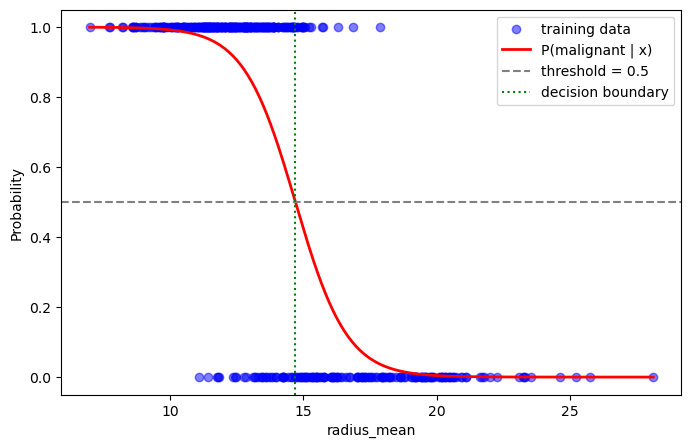

In [16]:

x_range = np.linspace(x.min(), x.max(), 300).reshape(-1, 1)
p_range = log_reg.predict_proba(x_range)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, alpha=0.5, label="training data", color="blue")
plt.plot(x_range, p_range, color="red", label="P(malignant | x)", linewidth=2)
plt.axhline(0.5, color="gray", linestyle="--", label="threshold = 0.5")
plt.axvline(-b / w, color="green", linestyle=":", label="decision boundary")
plt.xlabel("radius_mean")
plt.ylabel("Probability")
plt.legend()
plt.show()

In [18]:

new_patient = [[14.5]]


prob = log_reg.predict_proba(new_patient)[0, 1]
print(f"Probability of being Benign: {prob:.3f}")


prediction = log_reg.predict(new_patient)[0]
result_text = "Benign " if prediction == 1 else "Malignant "
print(f"Prediction: {result_text}")

Probability of being Benign: 0.550
Prediction: Benign 
